In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### Import and Processing Image

In [7]:
img = cv2.imread('../img/mnist_08.jpg')

In [8]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

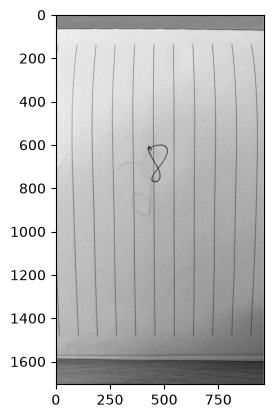

In [9]:
plt.imshow(gray, cmap='gray')

In [10]:
blurred = cv2.GaussianBlur(src=gray, ksize=(11, 11), sigmaX=0)

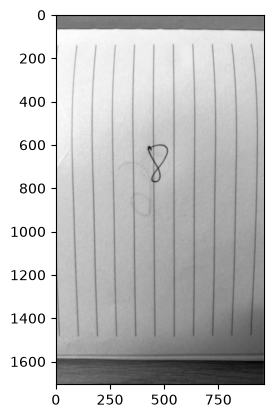

In [11]:
plt.imshow(blurred, cmap='gray')

In [12]:
def auto_canny(img):
    lower = 100
    upper = 200
    edged = cv2.Canny(image=img, threshold1=lower, threshold2=upper)
    return edged

In [13]:
ret, thresh = cv2.threshold(src=blurred, thresh=0, maxval=255, type=cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

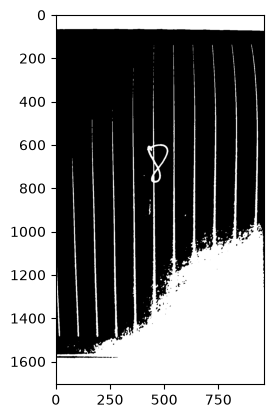

In [14]:
plt.imshow(thresh, cmap='gray')

In [15]:
sharpen_kernel = np.array([[ 0,    -0.25,  0],
                           [-0.25,  2.0,  -0.25],
                           [ 0,    -0.25,  0]])
sharp_img = cv2.filter2D(blurred, -1, sharpen_kernel)

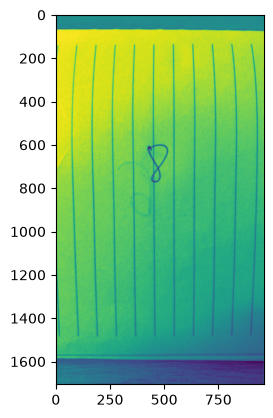

In [16]:
plt.imshow(blurred)

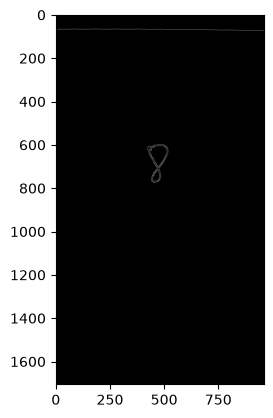

In [17]:
canny_edges = auto_canny(img=sharp_img)
plt.imshow(canny_edges, cmap='gray')

In [533]:
contours, hierarchy = cv2.findContours(image=canny_edges, mode=cv2.RETR_TREE, method=cv2.CHAIN_APPROX_NONE)

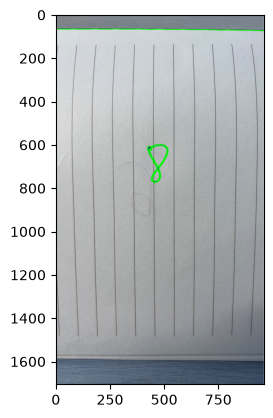

In [534]:
img_copy = img.copy()
cv2.drawContours(image=img_copy, contours=contours, contourIdx=-1, color=(0, 255, 0), thickness=2, lineType=cv2.LINE_AA)
plt.imshow(img_copy, cmap='gray')

In [535]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
dilate_img = cv2.dilate(canny_edges, kernel)

Image size: 960x1706


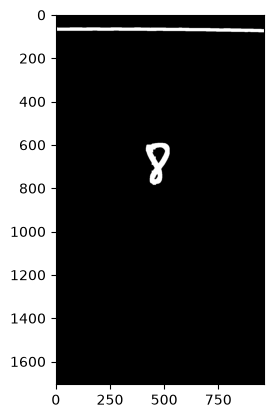

In [536]:
plt.imshow(dilate_img, cmap='gray')
h, w = img.shape[:2]
print(f'Image size: {w}x{h}')

In [4]:
def advanced_processing_digit(img, target_size=(28, 28)):
    contours, _ = cv2.findContours(
        img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    
    if not contours:
        resized = cv2.resize(img, target_size, interpolation=cv2.INTER_LANCZOS4)
        return resized, resized.reshape(1, 784)
    valid_contours = []
    img_h, img_w = img.shape
    
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        area = cv2.contourArea(c)

        if area < 50:
            continue
        
        if w > img_w * 0.7 or h > img_h * 0.7:
            continue

        aspect_ratio = float(w) / h
        if aspect_ratio < 0.1 or aspect_ratio > 3.0:
            continue

        valid_contours.append(c)

    if not valid_contours:
        largest_contour = max(contours, key=cv2.contourArea)
    else:
        largest_contour = max(valid_contours, key=cv2.contourArea)

    x, y, w, h = cv2.boundingRect(largest_contour)
    digit_crop = img[y : y + h, x : x + w]
    
    max_side = max(w, h)
    pad_size = int(max_side * 1.4)
    digit_padded = np.zeros((pad_size, pad_size), dtype=np.uint8)
    
    offset_x = (pad_size - w) // 2
    offset_y = (pad_size - h) // 2
    digit_padded[offset_y:offset_y+h, offset_x:offset_x+w] = digit_crop
    
    resized_img = cv2.resize(digit_padded, target_size, interpolation=cv2.INTER_CUBIC)
    
    input_matrix = resized_img.reshape(1, 784)
    
    return resized_img, input_matrix

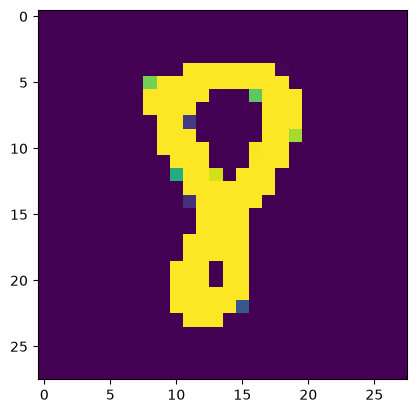

In [540]:
advanced_processing_img, _ = advanced_processing_digit(dilate_img)
plt.imshow(advanced_processing_img)

In [3]:
def processing_img(img, 
                   target_size=(28, 28), 
                   sharpen_kernel= np.array([[ 0,    -0.25,  0],
                                             [-0.25,  2.0,  -0.25],
                                             [ 0,    -0.25,  0]])):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(src=gray, ksize=(11, 11), sigmaX=0)
    sharp_img = cv2.filter2D(blurred, -1, sharpen_kernel)
    canny_edges = auto_canny(img=sharp_img)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    dilate_img = cv2.dilate(canny_edges, kernel)
    processed_img, input_matrix = advanced_processing_digit(dilate_img, target_size)
    return processed_img, input_matrix
    

In [19]:
imgs = [cv2.imread('../img/mnist_00.jpg'), cv2.imread('../img/mnist_01.jpg'), cv2.imread('../img/mnist_02.jpg'), cv2.imread('../img/mnist_03.jpg'), cv2.imread('../img/mnist_04.jpg'), cv2.imread('../img/mnist_05.jpg'), cv2.imread('../img/mnist_06.jpg'), cv2.imread('../img/mnist_07.jpg'), cv2.imread('../img/mnist_08.jpg'), cv2.imread('../img/mnist_09.jpg')]
processed_img_00, input_matrix_00 = processing_img(imgs[0])
processed_img_01, input_matrix_01 = processing_img(imgs[1])
processed_img_02, input_matrix_02 = processing_img(imgs[2])
processed_img_03, input_matrix_03 = processing_img(imgs[3])
processed_img_04, input_matrix_04 = processing_img(imgs[4])
processed_img_05, input_matrix_05 = processing_img(imgs[5])
processed_img_06, input_matrix_06 = processing_img(imgs[6])
processed_img_07, input_matrix_07 = processing_img(imgs[7])
processed_img_08, input_matrix_08 = processing_img(imgs[8])
processed_img_09, input_matrix_09 = processing_img(imgs[9])

In [20]:
processed_imgs = [processed_img_00, processed_img_01, processed_img_02, processed_img_03, processed_img_04, processed_img_05, processed_img_06, processed_img_07, processed_img_08, processed_img_09]
input_matrixs = [input_matrix_00, input_matrix_01, input_matrix_02, input_matrix_03, input_matrix_04, input_matrix_05, input_matrix_06, input_matrix_07, input_matrix_08, input_matrix_09]
final_batch_input = np.vstack(input_matrixs)

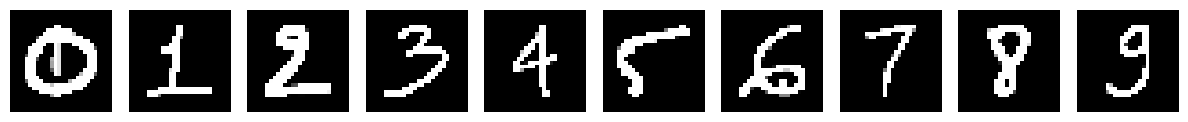

In [21]:
plt.figure(figsize=(12, 6))
for i in range(len(processed_imgs)):
    plt.subplot(5, 10, i + 1)
    plt.imshow(processed_imgs[i], cmap='gray')
    plt.axis('off')
plt.tight_layout()
plt.show()

### Import Model and Check

In [31]:
import os
import sys
sys.dont_write_bytecode = True
sys.path.append(os.path.abspath("../"))
from src.clazz.MultilayerPerceptron import MultilayerPerceptron
multilayer = MultilayerPerceptron()

In [32]:
model_data = np.load('../src/model/mlp_model.npz')
print(f'The infomation of model_data: {model_data}')

The infomation of model_data: NpzFile '../src/model/mlp_model.npz' with keys: W_0, W_1, b_0, b_1


In [575]:
multilayer.set_W([model_data['W_0'], model_data['W_1']])
multilayer.set_b([model_data['b_0'], model_data['b_1']])

In [590]:
result = multilayer.predict(input_matrix_07)
print(f'Predicted result is: {result}')

Predicted result is: [8]


In [588]:
result = multilayer.predict(final_batch_input)
print(f'Predicted result is: {result}')

Predicted result is: [0 6 2 6 4 2 6 8 8 3]


### Test with MNIST Dataset

In [36]:
import tensorflow as tf

In [37]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

In [43]:
X_flatten = X_test.reshape(X_test.shape[0], -1)

In [ ]:
X_flatten

In [44]:
X_flatten.shape

(10000, 784)

In [45]:
results = multilayer.predict(X_flatten)

### Save the input matrix

In [23]:
def save_matrix(filename, matrix):
    matrix = np.asarray(matrix)

    if matrix.ndim != 2:
        raise Exception("Matrix must be 2-dimensional.")

    rows, cols = matrix.shape

    with open(filename, "w", encoding="utf-8") as f:
        f.write(f"{rows} {cols}\n")
        np.savetxt(f, matrix, fmt="%.8f")

In [28]:
save_matrix('../src/model/matrix_00.txt', input_matrix_00)
save_matrix('../src/model/matrix_01.txt', input_matrix_01)
save_matrix('../src/model/matrix_02.txt', input_matrix_02)
save_matrix('../src/model/matrix_03.txt', input_matrix_03)
save_matrix('../src/model/matrix_04.txt', input_matrix_04)
save_matrix('../src/model/matrix_05.txt', input_matrix_05)
save_matrix('../src/model/matrix_06.txt', input_matrix_06)
save_matrix('../src/model/matrix_07.txt', input_matrix_07)
save_matrix('../src/model/matrix_08.txt', input_matrix_08)
save_matrix('../src/model/matrix_09.txt', input_matrix_09)

## Save the value of Weight and Bias

In [34]:
from pathlib import Path

In [29]:
def save_matrix(name, output_dir, array):
    array = np.ascontiguousarray(array, dtype=np.float32)

    if array.ndim != 2:
        raise ValueError(f"{name} must be a 2D matrix, got {array.shape}")

    path = output_dir / f"{name}.bin"

    with path.open("wb") as f:
        np.asarray(array.shape, dtype="<i4").tofile(f)
        array.astype("<f4", copy=False).tofile(f)

    print(f"{name}: shape={array.shape}, saved={path}")

In [37]:
output_dir = Path("../src/model")
output_dir.mkdir(parents=True, exist_ok=True)
for name in ['W_0', 'W_1', 'b_0', 'b_1']:
    save_matrix(name, output_dir, model_data[name])

W_0: shape=(784, 128), saved=../src/model/W_0.bin
W_1: shape=(128, 10), saved=../src/model/W_1.bin
b_0: shape=(1, 128), saved=../src/model/b_0.bin
b_1: shape=(1, 10), saved=../src/model/b_1.bin
